### Step 1: Data Exploration (EDA)  

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings 

warnings.filterwarnings("ignore")

# Load dataset (Replace 'mobile_data.csv' with your actual file path if needed)
df = pd.read_excel('Processed_Flipdata.xlsx')

# Drop the unnecessary index column if redundant
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

# Basic Info & Summary Statistics
print("Dataset Shape:", df.shape)
print(df.info())
print(df.describe())

# Check for missing values
print("\nMissing Values:\n", df.isnull().sum())

Dataset Shape: (541, 11)
<class 'pandas.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Model          541 non-null    str    
 1   Colour         541 non-null    str    
 2   Memory         541 non-null    int64  
 3   RAM            541 non-null    int64  
 4   Battery_       541 non-null    int64  
 5   Rear Camera    541 non-null    str    
 6   Front Camera   541 non-null    str    
 7   AI Lens        541 non-null    int64  
 8   Mobile Height  541 non-null    float64
 9   Processor_     541 non-null    str    
 10  Prize          541 non-null    int64  
dtypes: float64(1), int64(5), str(5)
memory usage: 46.6 KB
None
           Memory         RAM     Battery_     AI Lens  Mobile Height  \
count  541.000000  541.000000   541.000000  541.000000     541.000000   
mean   110.550832    5.397412  4871.587800    0.062847      16.431201   
std     60.600694    1.984

In [2]:
df.head()

,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
0,Infinix SMART 7,Night Black,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
1,Infinix SMART 7,Azure Blue,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
2,MOTOROLA G32,Mineral Gray,128,8,5000,50MP,16MP,0,16.64,Qualcomm Snapdragon 680,11999
3,POCO C50,Royal Blue,32,2,5000,8MP,5MP,0,16.56,Mediatek Helio A22,5649
4,Infinix HOT 30i,Marigold,128,8,5000,50MP,5MP,1,16.76,G37,8999


#### Analysis & Visualization:

Analysis: We verify data types to ensure numerical features (Memory, RAM, Battery_, Mobile Height, Prize) are correctly parsed, and categorical features (Model, Colour, Processor_, etc.) are recognized as strings/objects.

Diagram/Visualization: Correlation Heatmap to spot linear relationships between numerical features and the target (Prize).

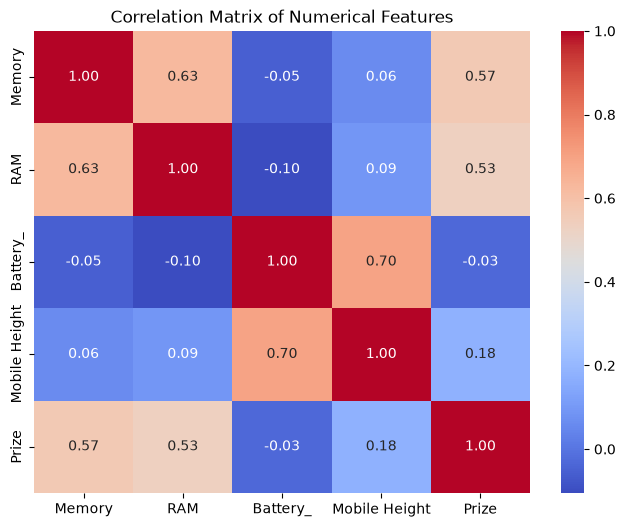

In [3]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[['Memory', 'RAM', 'Battery_', 'Mobile Height', 'Prize']].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numerical Features')
plt.show()

### Step 2: Data Preprocessing & Cleaning
Objective: Handle missing values, clean string-based camera columns into numeric values, and encode categorical variables.


In [4]:
# 1. Clean Camera columns (Extract numeric integer values from strings like '64MP' -> 64)
df['Rear Camera'] = df['Rear Camera'].str.extract(r'(\d+)').astype(float)
df['Front Camera'] = df['Front Camera'].str.extract(r'(\d+)').astype(float)

# 2. Handle Missing Values (Impute numeric with median, categorical with mode)
for col in ['Memory', 'RAM', 'Battery_', 'Rear Camera', 'Front Camera']:
    df[col].fillna(df[col].median(), inplace=True)

for col in ['Model', 'Colour', 'Processor_']:
    df[col].fillna(df[col].mode()[0], inplace=True)

# 3. Separate Features (X) and Target (y)
X = df.drop(columns=['Prize'])
y = df['Prize']

# 4. Identify Categorical and Numerical columns for Preprocessing
categorical_cols = ['Model', 'Colour', 'Processor_']
numerical_cols = [col for col in X.columns if col not in categorical_cols]

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

### Step 3: Feature Extraction & Engineering
Objective: Transform raw features into high-performing predictors. By converting camera text attributes into numeric megapixel counts and scaling continuous variables, we ensure machine learning algorithms can effectively compute weights.

## Step 4: Model Building
Objective: Split the dataset into training and testing sets, then train a robust regression model (Random Forest Regressor) to predict mobile prices.



In [5]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

# Train-Test Split (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Build pipeline with Preprocessing and Random Forest Regressor
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42))
])

# Train the model
model_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['Model','Colour','Memory',...,'AI Lens','Mobile Height','Processor_']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of colu

### Step 5: Model EvaluationObjective: Evaluate prediction accuracy using standard regression metrics: Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the Coefficient of Determination ($R^2$).

In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred = model_pipeline.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Model Evaluation Metrics:")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R² Score: {r2:.4f}")

Model Evaluation Metrics:
Mean Absolute Error (MAE): 1809.14
Root Mean Squared Error (RMSE): 4568.79
R² Score: 0.8486


###  Step 6: Feature Importance Analysis
Objective: Extract feature importances from the trained Random Forest model to verify which specifications dictate market price the most.



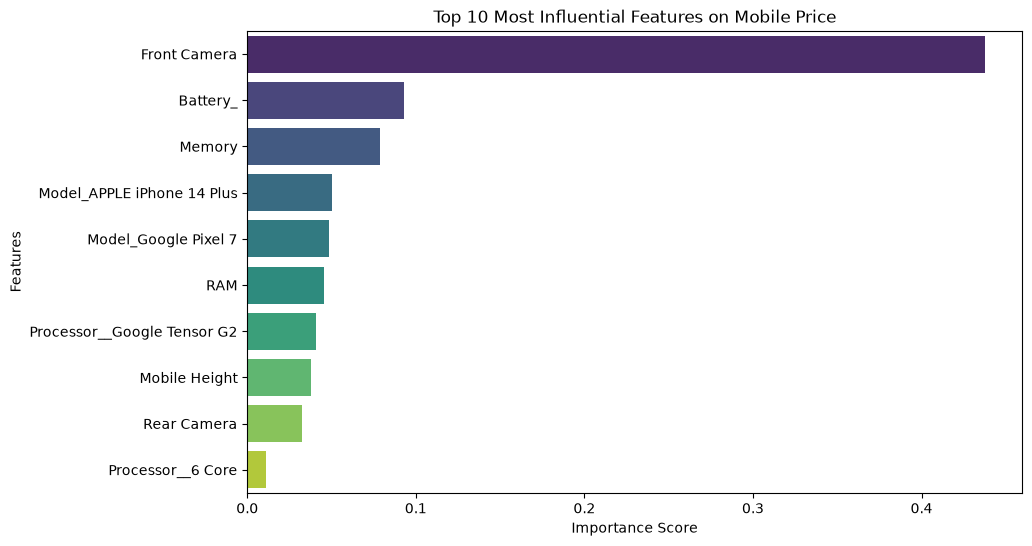

In [7]:
# Extract feature names after One-Hot Encoding
cat_encoder = model_pipeline.named_steps['preprocessor'].named_transformers_['cat']
encoded_cat_cols = list(cat_encoder.get_feature_names_out(categorical_cols))
all_features = numerical_cols + encoded_cat_cols

# Get feature importances
importances = model_pipeline.named_steps['regressor'].feature_importances_

# Create a summary dataframe
feature_importance_df = pd.DataFrame({'Feature': all_features, 'Importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

# Plot Top Features
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df.head(10), palette='viridis')
plt.title('Top 10 Most Influential Features on Mobile Price')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()